# Westbridge Retail: Sales & Customer Analytics (SQL + Python)

**Note: all data in this project is synthetic.** It was generated by `scripts/generate_data.py` with a fixed random seed. Westbridge Retail is a fictional company.

## 1. Business overview

Westbridge Retail sells through physical stores and online. Management wants to understand four things:

1. **Sales performance:** how much revenue do we earn, and how does it vary by month, channel and region?
2. **Product profitability:** which products and categories drive revenue and gross profit?
3. **Customer behaviour:** how many customers come back, and how much do they spend?
4. **Customer retention:** which customers are valuable, and which are drifting away?

**Data available** (January 2024 - December 2025): `customers`, `categories`, `products`, `orders`, `order_items` in a SQLite database.

**Approach:** the business calculations are written in SQL (`sql/analysis/*.sql`). This notebook runs those scripts through `src/database.py`, loads the results into pandas, checks them, and draws the charts.

**Definitions used throughout**
- Line revenue = `quantity * unit_price - discount_amount`
- Line gross profit = line revenue - `quantity * unit_cost`. This is *gross* profit only. The data has no rent, payroll, shipping or marketing costs, so net profit cannot be calculated.
- KPIs count **completed** orders only. Cancelled orders are kept in the database and analysed separately.

## 2. Database connection

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

# Find the repository root whether Jupyter was started in the root or in notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.analysis import (PALETTE, add_month_start, business_rule_checks, column_types,
                          date_coverage, duplicate_key_report, format_currency,
                          format_currency_short, growth_for_plot, missing_values_report,
                          referential_integrity_report, run_validated,
                          sales_consistency_check, table_row_counts)
from src.database import DB_PATH, get_connection, load_sql_file, run_query

CHART_DIR = PROJECT_ROOT / "assets" / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": PALETTE["dark_gray"], "axes.labelcolor": PALETTE["dark_gray"],
    "xtick.color": PALETTE["dark_gray"], "ytick.color": PALETTE["dark_gray"],
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlecolor": PALETTE["navy"],
    "grid.color": "#E5E7EB", "figure.dpi": 110,
})

print("Database:", DB_PATH.relative_to(PROJECT_ROOT))
with get_connection() as connection:
    foreign_keys_on = connection.execute("PRAGMA foreign_keys").fetchone()[0]
    sqlite_version = connection.execute("SELECT sqlite_version()").fetchone()[0]
print("SQLite version:", sqlite_version, "| foreign keys enforced:", bool(foreign_keys_on))

Database: database/retail_analytics.db
SQLite version: 3.45.1 | foreign keys enforced: True


Each SQL file contains several named queries. `load_sql_file` splits a file into `{name: sql}`, and `run_validated` runs one and returns a pandas DataFrame after basic checks.

In [2]:
for sql_file in sorted((PROJECT_ROOT / "sql" / "analysis").glob("*.sql")):
    print(f"{sql_file.name}: {', '.join(load_sql_file(sql_file.name))}")

01_sales_performance.sql: kpi_summary, monthly_revenue, revenue_by_channel, revenue_by_region, cancellations_by_channel
02_product_performance.sql: top_products_by_revenue, top_products_by_units, revenue_by_category, gross_profit_by_product, margin_by_category, low_activity_products
03_customer_behavior.sql: customer_counts, customer_spending, spending_summary, top_customers_by_spending, purchase_frequency_distribution, customers_without_purchases
04_monthly_growth.sql: monthly_growth
05_customer_segmentation.sql: rfm_customer_segments, rfm_segment_summary
06_advanced_queries.sql: best_product_per_category, top_categories_by_region, channel_mix_by_category, category_growth_2025_vs_2024, repurchase_interval, first_channel_and_retention, discount_impact_on_margin, underperforming_products_vs_category, customers_above_twice_average


In [3]:
# Example: the SQL text behind one query, and its result as a DataFrame
print(load_sql_file("01_sales_performance.sql")["kpi_summary"])
run_validated("01_sales_performance.sql", "kpi_summary", required_columns=["net_revenue", "completed_orders"])

-- Headline KPIs for completed orders: orders, units, gross sales, discounts,
-- net revenue and average order value (net revenue / completed orders).
SELECT
    COUNT(DISTINCT o.order_id)                                         AS completed_orders,
    SUM(oi.quantity)                                                   AS units_sold,
    ROUND(SUM(oi.quantity * oi.unit_price), 2)                         AS gross_sales,
    ROUND(SUM(oi.discount_amount), 2)                                  AS total_discounts,
    ROUND(SUM(oi.quantity * oi.unit_price - oi.discount_amount), 2)    AS net_revenue,
    ROUND(SUM(oi.quantity * oi.unit_price - oi.discount_amount)
          / COUNT(DISTINCT o.order_id), 2)                             AS avg_order_value
FROM orders AS o
JOIN order_items AS oi ON oi.order_id = o.order_id
WHERE o.order_status = 'Completed';


,completed_orders,units_sold,gross_sales,total_discounts,net_revenue,avg_order_value
0,14272,39590,"1,690,828.60","54,008.07","1,636,820.53",114.69


## 3. Data inspection

In [4]:
display(table_row_counts())
display(column_types().query("pk == 1 or `table` == 'order_items'"))

,table,rows
0,categories,12
1,customers,1000
2,products,100
3,orders,15000
4,order_items,29742


,table,name,type,notnull,pk
0,categories,category_id,INTEGER,0,1
2,customers,customer_id,INTEGER,0,1
9,products,product_id,INTEGER,0,1
14,orders,order_id,INTEGER,0,1
19,order_items,order_item_id,INTEGER,0,1
20,order_items,order_id,INTEGER,1,0
21,order_items,product_id,INTEGER,1,0
22,order_items,quantity,INTEGER,1,0
23,order_items,unit_price,REAL,1,0
24,order_items,discount_amount,REAL,1,0


In [5]:
missing = missing_values_report()
print("Columns with missing values:", int((missing["missing_values"] > 0).sum()), "of", len(missing))
display(duplicate_key_report())
display(referential_integrity_report())
display(date_coverage())

Columns with missing values: 0 of 25


,table,primary_key,duplicate_keys
0,categories,category_id,0
1,customers,customer_id,0
2,products,product_id,0
3,orders,order_id,0
4,order_items,order_item_id,0


,relationship,orphan_rows
0,products.category_id -> categories.category_id,0
1,orders.customer_id -> customers.customer_id,0
2,order_items.order_id -> orders.order_id,0
3,order_items.product_id -> products.product_id,0


,date_column,first_date,last_date,distinct_months
0,orders.order_date,2024-01-01,2025-12-31,24
1,customers.registration_date,2023-01-05,2025-10-25,34


In [6]:
display(business_rule_checks())
consistency = sales_consistency_check()
display(consistency)
print(f"Cancelled-order revenue excluded from KPIs: ${consistency.attrs['cancelled_revenue_excluded']:,.2f}")
assert consistency["matches"].all(), "SQL results disagree with the pandas recalculation"

,rule,violations
0,Discount greater than gross line amount,0
1,Order line price differs from product list price,0
2,Order placed before customer registration,0
3,Order without any order lines,0
4,Order date outside Jan 2024 - Dec 2025,0
5,Unit cost not below unit price,0


,check,pandas_value,sql_value,difference,matches
0,Net revenue (completed orders),"1,636,820.53","1,636,820.53",0.00,True
1,Net revenue - sum of monthly query,"1,636,820.53","1,636,820.53",0.00,True
2,Completed orders,"14,272.00","14,272.00",0.00,True
3,Gross profit - sum of product query,"606,266.47","606,266.47",0.00,True


Cancelled-order revenue excluded from KPIs: $80,358.36


All primary keys are unique, every foreign key has a parent row, no business rule is violated, and the SQL totals match an independent pandas recalculation from the raw tables.

## 4. Sales performance

In [7]:
kpi = run_validated("01_sales_performance.sql", "kpi_summary", min_rows=1)
display(kpi)
kpi_row = kpi.iloc[0]
print(f"Net revenue: ${kpi_row['net_revenue']:,.2f} | completed orders: {kpi_row['completed_orders']:,} | "
      f"average order value: ${kpi_row['avg_order_value']:,.2f} | units sold: {kpi_row['units_sold']:,}")

,completed_orders,units_sold,gross_sales,total_discounts,net_revenue,avg_order_value
0,14272,39590,"1,690,828.60","54,008.07","1,636,820.53",114.69


Net revenue: $1,636,820.53 | completed orders: 14,272.0 | average order value: $114.69 | units sold: 39,590.0


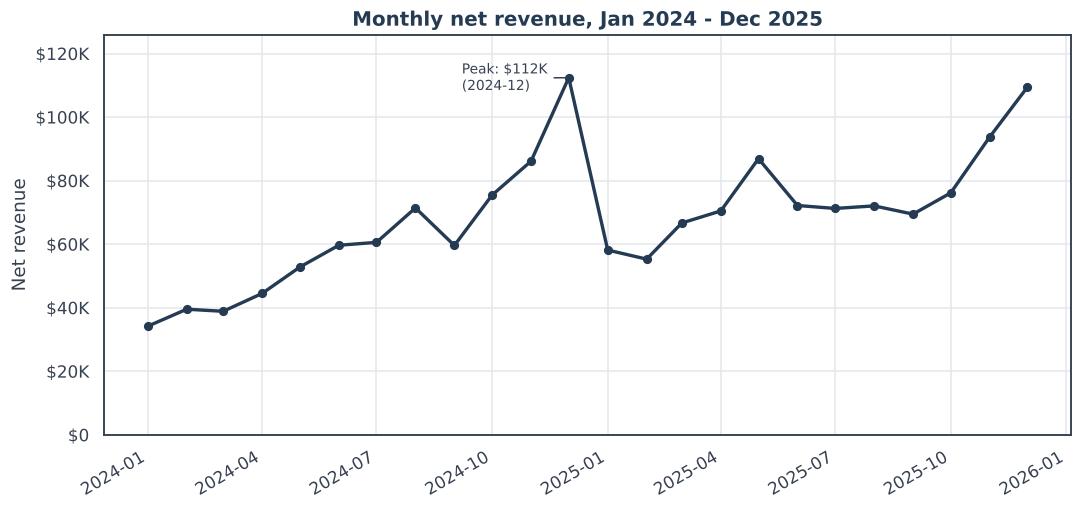

In [8]:
monthly = run_validated("01_sales_performance.sql", "monthly_revenue", min_rows=24)
monthly = add_month_start(monthly)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(monthly["month_start"], monthly["net_revenue"], color=PALETTE["navy"], linewidth=2.2,
        marker="o", markersize=5)
ax.set_title("Monthly net revenue, Jan 2024 - Dec 2025")
ax.set_xlabel("")
ax.set_ylabel("Net revenue")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_currency_short))
ax.set_ylim(0, monthly["net_revenue"].max() * 1.12)
peak = monthly.loc[monthly["net_revenue"].idxmax()]
ax.annotate(f"Peak: {format_currency_short(peak['net_revenue'])}\n({peak['order_month']})",
            (peak["month_start"], peak["net_revenue"]), textcoords="offset points", xytext=(-70, -8),
            color=PALETTE["dark_gray"], fontsize=9, arrowprops=dict(arrowstyle="-", color=PALETTE["dark_gray"]))
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(CHART_DIR / "01_monthly_revenue_trend.png", dpi=150, bbox_inches="tight")
plt.show()

,sales_channel,completed_orders,units_sold,net_revenue,avg_order_value,revenue_share_pct
0,In-Store,7825,23772,"899,190.03",114.91,54.90
1,Online,6447,15818,"737,630.50",114.41,45.10


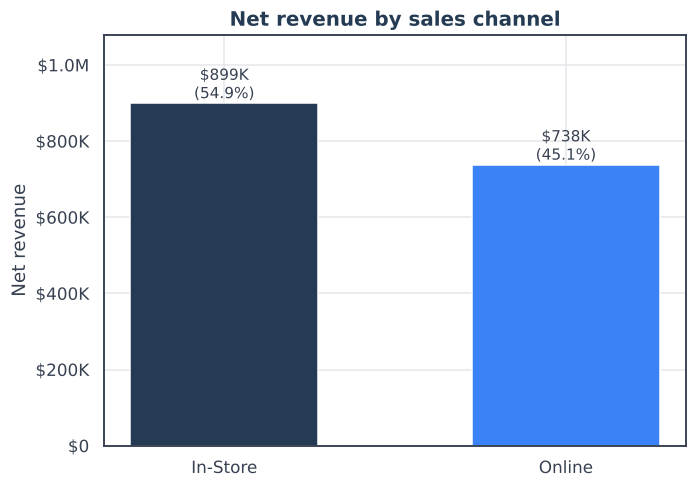

In [9]:
by_channel = run_validated("01_sales_performance.sql", "revenue_by_channel", min_rows=2)
display(by_channel)

fig, ax = plt.subplots(figsize=(6.5, 4.6))
bars = ax.bar(by_channel["sales_channel"], by_channel["net_revenue"],
              color=[PALETTE["navy"], PALETTE["blue"]], width=0.55)
for bar, share in zip(bars, by_channel["revenue_share_pct"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{format_currency_short(bar.get_height())}\n({share:.1f}%)", ha="center", va="bottom",
            fontsize=10, color=PALETTE["dark_gray"])
ax.set_title("Net revenue by sales channel")
ax.set_xlabel("")
ax.set_ylabel("Net revenue")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_currency_short))
ax.set_ylim(0, by_channel["net_revenue"].max() * 1.2)
fig.tight_layout()
fig.savefig(CHART_DIR / "04_revenue_by_channel.png", dpi=150, bbox_inches="tight")
plt.show()

,region,buying_customers,completed_orders,net_revenue,avg_order_value,revenue_share_pct
0,Northeast,203,3339,"379,863.72",113.77,23.20
1,Midwest,180,2916,"343,586.16",117.83,21.00
2,West,189,2917,"331,534.31",113.66,20.30
3,Southeast,176,2791,"304,604.44",109.14,18.60
4,Southwest,163,2309,"277,231.90",120.07,16.90


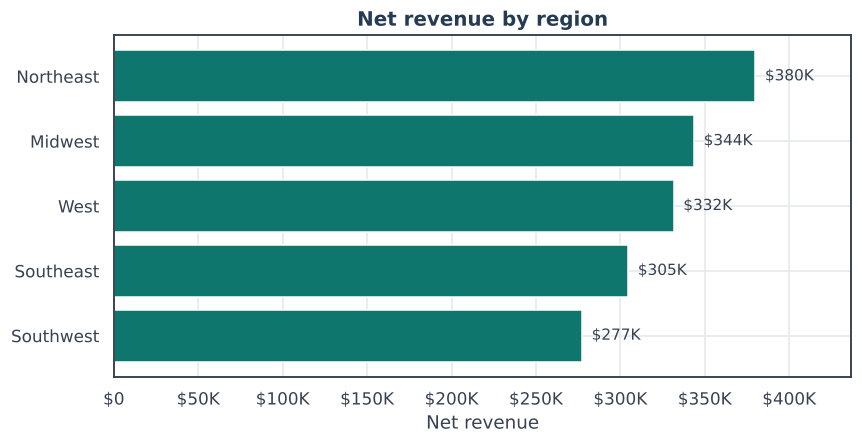

In [10]:
by_region = run_validated("01_sales_performance.sql", "revenue_by_region", min_rows=4)
display(by_region)

region_sorted = by_region.sort_values("net_revenue")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(region_sorted["region"], region_sorted["net_revenue"], color=PALETTE["teal"])
for y, value in enumerate(region_sorted["net_revenue"]):
    ax.text(value, y, f"  {format_currency_short(value)}", va="center", fontsize=10, color=PALETTE["dark_gray"])
ax.set_title("Net revenue by region")
ax.set_xlabel("Net revenue")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(format_currency_short))
ax.set_xlim(0, region_sorted["net_revenue"].max() * 1.15)
fig.tight_layout()
fig.savefig(CHART_DIR / "08_regional_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
cancellations = run_validated("01_sales_performance.sql", "cancellations_by_channel", min_rows=2)
display(cancellations)

,sales_channel,total_orders,cancelled_orders,cancellation_rate_pct,cancelled_value
0,In-Store,8068,243,3.01,"29,353.11"
1,Online,6932,485,7.00,"51,005.25"


## 5. Product analysis

,category_name,products_sold,units_sold,net_revenue,revenue_share_pct
0,Computers & Accessories,8,1574,"278,814.26",17.00
1,Sports & Outdoors,9,5636,"217,442.97",13.30
2,Home & Kitchen,9,2986,"175,610.13",10.70
3,Women's Clothing,8,2158,"158,615.50",9.70
4,Men's Clothing,8,3115,"157,060.29",9.60
5,Electronics,9,1566,"139,314.84",8.50
6,Grocery & Pantry,9,10862,"121,805.55",7.40
7,Books & Stationery,9,6082,"106,875.49",6.50
8,Furniture,7,354,"94,820.46",5.80
9,Beauty & Personal Care,9,3115,"88,729.96",5.40


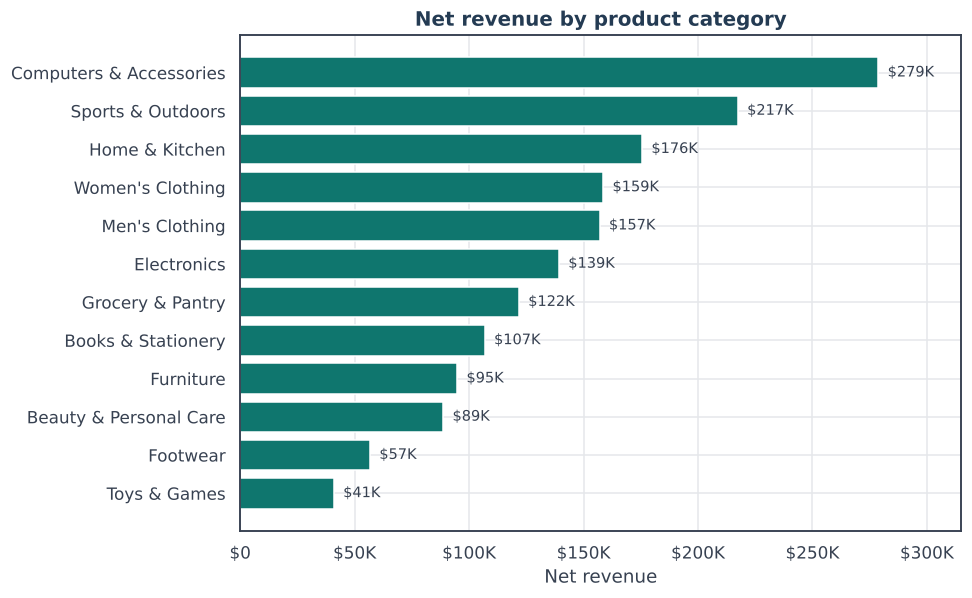

In [12]:
by_category = run_validated("02_product_performance.sql", "revenue_by_category", min_rows=10)
display(by_category)

category_sorted = by_category.sort_values("net_revenue")
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.barh(category_sorted["category_name"], category_sorted["net_revenue"], color=PALETTE["teal"])
for y, value in enumerate(category_sorted["net_revenue"]):
    ax.text(value, y, f"  {format_currency_short(value)}", va="center", fontsize=9.5, color=PALETTE["dark_gray"])
ax.set_title("Net revenue by product category")
ax.set_xlabel("Net revenue")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(format_currency_short))
ax.set_xlim(0, category_sorted["net_revenue"].max() * 1.13)
fig.tight_layout()
fig.savefig(CHART_DIR / "02_revenue_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

,product_id,product_name,category_name,units_sold,net_revenue,gross_profit
0,10,Ultrabook 14-inch Laptop,Computers & Accessories,206,"181,977.94","30,234.22"
1,45,Cashmere Blend Cardigan,Women's Clothing,742,"78,505.09","46,124.21"
2,63,Road Bike Helmet,Sports & Outdoors,1054,"65,951.47","27,353.99"
3,41,Fleece Zip Hoodie,Men's Clothing,990,"57,245.12","30,148.82"
4,64,Foam Roller Deep Tissue,Sports & Outdoors,2543,"56,162.77","24,375.27"
5,5,Noise-Cancelling Headphones,Electronics,366,"53,673.84","9,073.08"
6,18,Stainless Steel Cookware Set,Home & Kitchen,399,"49,747.01","16,366.67"
7,100,Hot Sauce Gift Set,Grocery & Pantry,2423,"38,083.77","10,849.25"
8,98,Wildflower Honey Jar,Grocery & Pantry,3337,"31,158.10","6,664.52"
9,29,Standing Desk Adjustable,Furniture,81,"30,659.19","11,719.77"


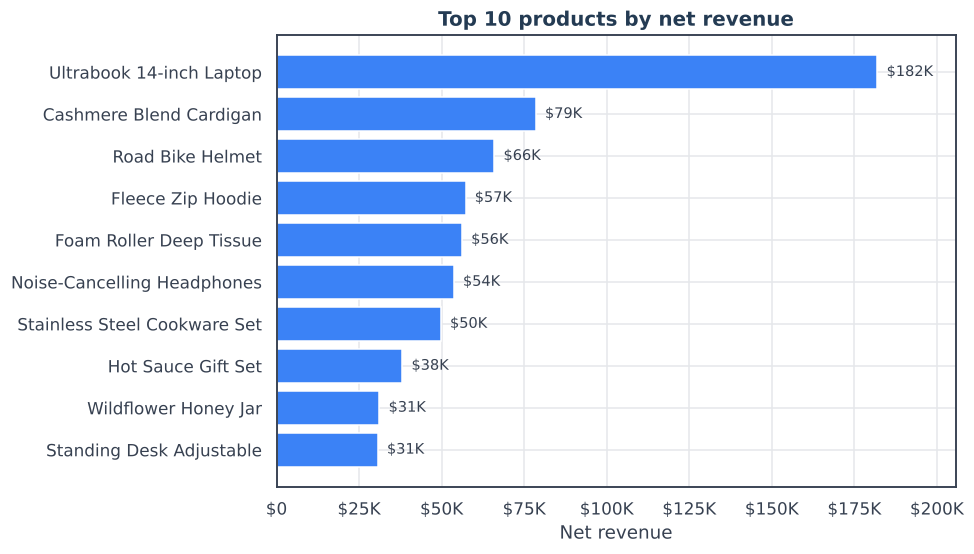

In [13]:
top_products = run_validated("02_product_performance.sql", "top_products_by_revenue", min_rows=10)
display(top_products)

products_sorted = top_products.sort_values("net_revenue")
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(products_sorted["product_name"], products_sorted["net_revenue"], color=PALETTE["blue"])
for y, value in enumerate(products_sorted["net_revenue"]):
    ax.text(value, y, f"  {format_currency_short(value)}", va="center", fontsize=9.5, color=PALETTE["dark_gray"])
ax.set_title("Top 10 products by net revenue")
ax.set_xlabel("Net revenue")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(format_currency_short))
ax.set_xlim(0, products_sorted["net_revenue"].max() * 1.13)
fig.tight_layout()
fig.savefig(CHART_DIR / "03_top_10_products_by_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
display(run_validated("02_product_performance.sql", "top_products_by_units", min_rows=10))

,product_id,product_name,category_name,units_sold,net_revenue
0,98,Wildflower Honey Jar,Grocery & Pantry,3337,"31,158.10"
1,64,Foam Roller Deep Tissue,Sports & Outdoors,2543,"56,162.77"
2,100,Hot Sauce Gift Set,Grocery & Pantry,2423,"38,083.77"
3,93,Organic Olive Oil 500ml,Grocery & Pantry,1660,"19,574.60"
4,89,Desk Planner 2025,Books & Stationery,1486,"21,447.35"
5,87,Business Strategy Paperback,Books & Stationery,1385,"25,288.65"
6,86,Gel Pen Set 24-Color,Books & Stationery,1330,"16,575.65"
7,63,Road Bike Helmet,Sports & Outdoors,1054,"65,951.47"
8,41,Fleece Zip Hoodie,Men's Clothing,990,"57,245.12"
9,38,Cotton Crew T-Shirt 3-Pack,Men's Clothing,932,"26,930.81"


**Gross profit and margin.** Gross profit = revenue - product cost. It is not net profit because operating expenses are not in the dataset.

In [15]:
margin = run_validated("02_product_performance.sql", "margin_by_category", min_rows=10)
display(margin)
display(run_validated("02_product_performance.sql", "gross_profit_by_product", min_rows=90).head(10))

,category_name,net_revenue,gross_profit,gross_margin_pct,discount_rate_pct
0,Beauty & Personal Care,"88,729.96","51,449.72",58.00,3.60
1,Women's Clothing,"158,615.50","91,203.39",57.50,3.70
2,Men's Clothing,"157,060.29","81,435.88",51.90,3.90
3,Footwear,"56,762.06","27,308.26",48.10,3.20
4,Toys & Games,"40,969.02","17,295.60",42.20,3.70
5,Sports & Outdoors,"217,442.97","89,999.13",41.40,3.70
6,Furniture,"94,820.46","39,237.14",41.40,4.80
7,Home & Kitchen,"175,610.13","65,069.70",37.10,3.80
8,Books & Stationery,"106,875.49","38,522.67",36.00,3.80
9,Grocery & Pantry,"121,805.55","30,090.94",24.70,1.70


,product_id,product_name,category_name,units_sold,net_revenue,cost_of_goods,gross_profit,gross_margin_pct
0,45,Cashmere Blend Cardigan,Women's Clothing,742,"78,505.09","32,380.88","46,124.21",58.80
1,10,Ultrabook 14-inch Laptop,Computers & Accessories,206,"181,977.94","151,743.72","30,234.22",16.60
2,41,Fleece Zip Hoodie,Men's Clothing,990,"57,245.12","27,096.30","30,148.82",52.70
3,63,Road Bike Helmet,Sports & Outdoors,1054,"65,951.47","38,597.48","27,353.99",41.50
4,64,Foam Roller Deep Tissue,Sports & Outdoors,2543,"56,162.77","31,787.50","24,375.27",43.40
5,18,Stainless Steel Cookware Set,Home & Kitchen,399,"49,747.01","33,380.34","16,366.67",32.90
6,38,Cotton Crew T-Shirt 3-Pack,Men's Clothing,932,"26,930.81","12,647.24","14,283.57",53.00
7,68,Electric Toothbrush,Beauty & Personal Care,425,"24,499.78","10,467.75","14,032.03",57.30
8,43,High-Rise Straight Jeans,Women's Clothing,339,"22,995.12","9,725.91","13,269.21",57.70
9,19,Programmable Coffee Maker,Home & Kitchen,430,"28,902.21","17,071.00","11,831.21",40.90


In [16]:
display(run_validated("02_product_performance.sql", "low_activity_products", min_rows=10))

,product_id,product_name,category_name,units_sold,net_revenue
0,21,Chef's Knife 8-inch,Home & Kitchen,5,224.95
1,28,Ergonomic Office Chair,Furniture,24,"5,699.76"
2,65,Sleeping Bag 20F,Sports & Outdoors,25,"2,150.75"
3,56,Leather Dress Loafers,Footwear,29,"2,804.71"
4,31,Queen Platform Bed Frame,Furniture,29,"12,329.71"
5,3,Smart Watch Series 4,Electronics,36,"7,049.64"
6,32,Walnut Coffee Table,Furniture,44,"6,623.56"
7,27,Oak Bookshelf 5-Tier,Furniture,47,"8,701.53"
8,9,Digital Camera Compact,Electronics,53,"17,093.47"
9,42,Linen Blend Blouse,Women's Clothing,55,"2,359.71"


## 6. Customer analysis

In [17]:
counts = run_validated("03_customer_behavior.sql", "customer_counts", min_rows=1)
display(counts.T.rename(columns={0: "value"}))
spending_summary = run_validated("03_customer_behavior.sql", "spending_summary", min_rows=1)
display(spending_summary.T.rename(columns={0: "value"}))

,value
registered_customers,"1,000.00"
customers_with_purchases,911.00
customers_without_purchases,89.00
one_time_customers,118.00
repeat_customers,793.00
repeat_rate_of_buyers_pct,87.00


,value
registered_customers,"1,000.00"
total_revenue,"1,636,820.53"
avg_revenue_per_registered_customer,"1,636.82"
avg_revenue_per_buying_customer,"1,796.73"
max_customer_revenue,"14,276.72"


In [18]:
customer_spending = run_validated("03_customer_behavior.sql", "customer_spending", min_rows=1000)
buyers = customer_spending[customer_spending["completed_orders"] > 0]
print(f"Median completed orders per buying customer: {buyers['completed_orders'].median():.0f}")
print(f"Median spend per buying customer: ${buyers['net_revenue'].median():,.2f} "
      f"(mean ${buyers['net_revenue'].mean():,.2f})")
display(run_validated("03_customer_behavior.sql", "top_customers_by_spending", min_rows=10))

Median completed orders per buying customer: 9
Median spend per buying customer: $971.46 (mean $1,796.73)


,customer_id,customer_name,region,completed_orders,net_revenue,avg_order_value
0,982,Levi Johnson,Northeast,73,"14,276.72",195.57
1,64,Logan Gonzalez,West,73,"11,949.80",163.70
2,132,Owen Bennett,Northeast,60,"11,045.42",184.09
3,284,Noah Delgado,Midwest,55,"10,927.30",198.68
4,996,Isaac Young,Midwest,64,"10,639.55",166.24
5,142,Lucas Cohen,Midwest,59,"10,556.17",178.92
6,987,Hiro Wong,Southeast,72,"10,501.90",145.86
7,63,Leo Anderson,Midwest,67,"9,536.60",142.34
8,245,Caroline Hassan,Southwest,46,"9,411.75",204.60
9,372,Daniel Murphy,Midwest,62,"8,689.06",140.15


,frequency_band,sort_order,customers
0,0 orders,1,89
1,1 order,2,118
2,2-5 orders,3,265
3,6-10 orders,4,103
4,11-20 orders,5,171
5,21-30 orders,6,102
6,31+ orders,7,152


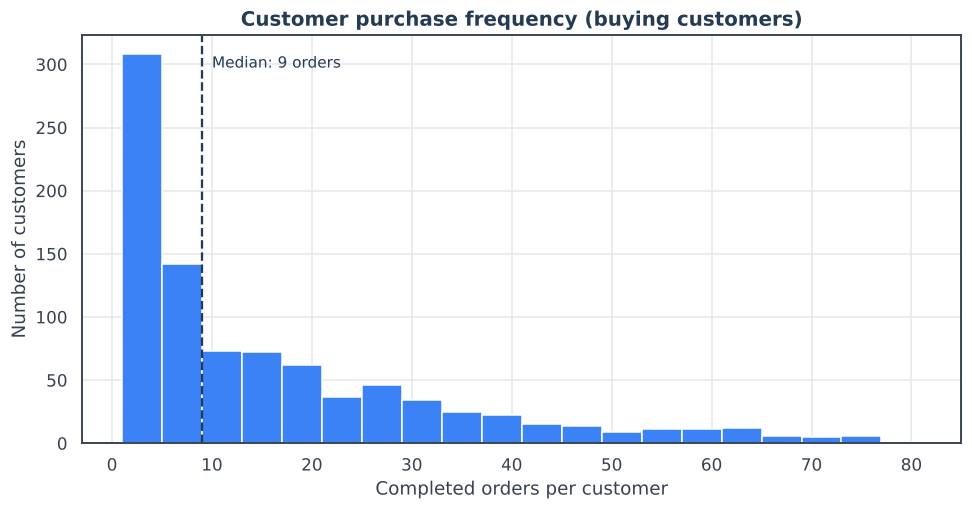

In [19]:
frequency = run_validated("03_customer_behavior.sql", "purchase_frequency_distribution", min_rows=5)
display(frequency)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.hist(buyers["completed_orders"], bins=range(1, int(buyers["completed_orders"].max()) + 5, 4),
        color=PALETTE["blue"], edgecolor="white")
ax.axvline(buyers["completed_orders"].median(), color=PALETTE["navy"], linestyle="--", linewidth=1.5)
ax.text(buyers["completed_orders"].median() + 1, ax.get_ylim()[1] * 0.92,
        f"Median: {buyers['completed_orders'].median():.0f} orders", color=PALETTE["navy"], fontsize=10)
ax.set_title("Customer purchase frequency (buying customers)")
ax.set_xlabel("Completed orders per customer")
ax.set_ylabel("Number of customers")
fig.tight_layout()
fig.savefig(CHART_DIR / "06_customer_purchase_frequency.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
display(run_validated("03_customer_behavior.sql", "customers_without_purchases", min_rows=1)["reason"].value_counts().to_frame("customers"))

,customers
reason,
Never ordered,85
Only cancelled orders,4


### Customer segments (RFM)

Reference date: **2025-12-31** (the end of the data), not today's date. Recency, frequency and monetary values are calculated from completed orders. Frequency and monetary value are scored 1-5 with `NTILE(5)`. Rules are applied in this order:

| Segment | Rule |
|---|---|
| No Purchases | no completed orders |
| At-Risk | last completed order more than 120 days before 2025-12-31 |
| High-Value | not At-Risk, frequency score >= 4 and monetary score >= 4 |
| Regular | not At-Risk, frequency score >= 3 |
| Occasional | all other active buyers |

,segment,customers,customer_share_pct,total_revenue,revenue_share_pct,avg_orders,avg_revenue_per_customer,avg_recency_days
0,High-Value,269,26.90,"1,081,459.21",66.10,34.50,"4,020.29",14.00
1,Regular,143,14.30,"151,133.69",9.20,10.40,"1,056.88",30.00
2,Occasional,141,14.10,"47,247.11",2.90,3.00,335.09,44.00
3,At-Risk,358,35.80,"356,980.52",21.80,8.60,997.15,330.00
4,No Purchases,89,8.90,0.00,0.00,NaN,NaN,NaN


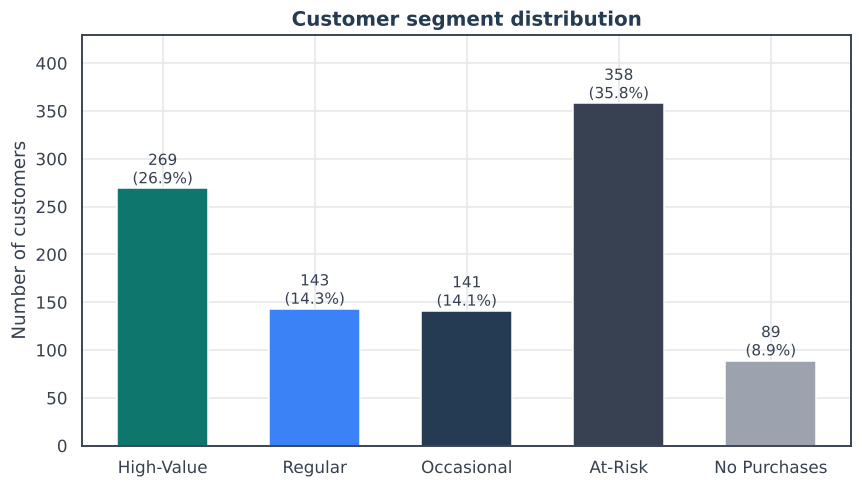

In [21]:
segments = run_validated("05_customer_segmentation.sql", "rfm_segment_summary", min_rows=5)
display(segments)

segment_colors = {"High-Value": PALETTE["teal"], "Regular": PALETTE["blue"], "Occasional": PALETTE["navy"],
                  "At-Risk": PALETTE["dark_gray"], "No Purchases": "#9CA3AF"}
fig, ax = plt.subplots(figsize=(8, 4.6))
bars = ax.bar(segments["segment"], segments["customers"],
              color=[segment_colors[s] for s in segments["segment"]], width=0.6)
for bar, share in zip(bars, segments["customer_share_pct"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{int(bar.get_height())}\n({share:.1f}%)",
            ha="center", va="bottom", fontsize=10, color=PALETTE["dark_gray"])
ax.set_title("Customer segment distribution")
ax.set_xlabel("")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, segments["customers"].max() * 1.2)
fig.tight_layout()
fig.savefig(CHART_DIR / "07_customer_segments.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
rfm_customers = run_validated("05_customer_segmentation.sql", "rfm_customer_segments", min_rows=1000)
print("Customers per segment:", rfm_customers["segment"].value_counts().to_dict())
print("Rows:", len(rfm_customers), "(equals registered customers)")
display(rfm_customers.head(8))

Customers per segment: {'At-Risk': 358, 'High-Value': 269, 'Regular': 143, 'Occasional': 141, 'No Purchases': 89}
Rows: 1000 (equals registered customers)


,customer_id,customer_name,recency_days,frequency,monetary,f_score,m_score,segment
0,1,Mason Ramirez,49.00,6.00,534.28,3.00,2.00,Regular
1,2,Hiro Hughes,2.00,29.00,"1,934.80",5.00,4.00,High-Value
2,3,Jacob Alvarez,349.00,1.00,97.10,1.00,1.00,At-Risk
3,4,Violet Ortiz,623.00,1.00,66.96,1.00,1.00,At-Risk
4,5,Jack Bennett,11.00,2.00,"1,088.96",1.00,3.00,Occasional
5,6,Natalie Kowalski,NaN,NaN,NaN,NaN,NaN,No Purchases
6,7,Michael Grant,352.00,18.00,"1,346.41",4.00,3.00,At-Risk
7,8,Sofia Oliver,390.00,11.00,"1,283.58",3.00,3.00,At-Risk


## 7. Monthly growth

`LAG(net_revenue, 1) OVER (ORDER BY order_month)` returns the revenue from the previous row in month order, so each month can be placed next to the month before it and growth is `(this month - previous month) / previous month`. The first month has no previous row, so its growth is `NULL` rather than 0. If the previous month were zero, growth is also `NULL`, because growth from zero is undefined. A recursive calendar CTE makes sure every month exists, so `LAG` always looks at the true previous calendar month. `LAG(..., 12)` gives the same month a year earlier for year-over-year growth.

,order_month,completed_orders,net_revenue,previous_month_revenue,mom_growth_pct,yoy_growth_pct,avg_order_value
0,2024-01,298,"34,178.91",NaN,NaN,NaN,114.69
1,2024-02,325,"39,524.33","34,178.91",15.64,NaN,121.61
2,2024-03,380,"38,874.24","39,524.33",-1.64,NaN,102.30
3,2024-04,386,"44,493.08","38,874.24",14.45,NaN,115.27
4,2024-05,449,"52,791.17","44,493.08",18.65,NaN,117.57
5,2024-06,480,"59,658.99","52,791.17",13.01,NaN,124.29


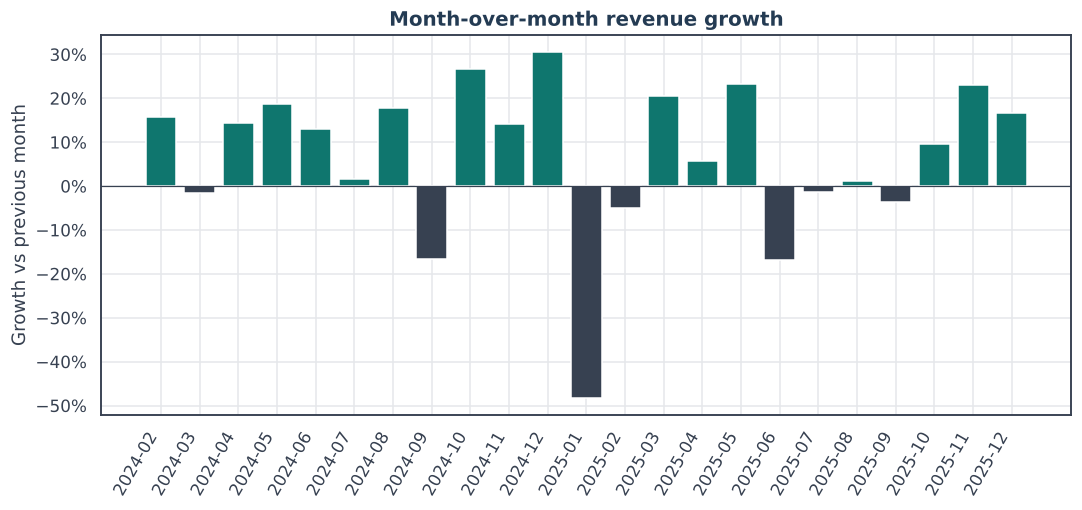

In [23]:
growth = run_validated("04_monthly_growth.sql", "monthly_growth", min_rows=24)
display(growth.head(6))
assert pd.isna(growth.loc[0, "mom_growth_pct"]), "First month should have no MoM growth"

plot_data = growth_for_plot(growth)
colors = plot_data["direction"].map({"Increase": PALETTE["teal"], "Decrease": PALETTE["dark_gray"]})
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(plot_data["order_month"], plot_data["mom_growth_pct"], color=colors)
ax.axhline(0, color=PALETTE["dark_gray"], linewidth=0.8)
ax.set_title("Month-over-month revenue growth")
ax.set_xlabel("")
ax.set_ylabel("Growth vs previous month")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
fig.tight_layout()
fig.savefig(CHART_DIR / "05_monthly_revenue_growth.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Findings

The text below is generated from the query results above, so the figures always match the data.

In [24]:
yearly = monthly.assign(year=monthly["month_start"].dt.year).groupby("year")["net_revenue"].sum()
growth_2025 = (yearly[2025] / yearly[2024] - 1) * 100
q4_share = monthly[monthly["month_start"].dt.month.isin([11, 12])].groupby(monthly["month_start"].dt.year)["net_revenue"].sum() / yearly
top_cat = by_category.iloc[0]
best_margin = margin.iloc[0]
worst_margin = margin.iloc[-1]
top_cat_margin = margin.set_index("category_name").loc[top_cat["category_name"]]
online = by_channel.set_index("sales_channel").loc["Online"]
store = by_channel.set_index("sales_channel").loc["In-Store"]
cancel = cancellations.set_index("sales_channel")
seg = segments.set_index("segment")
repeat_rate = counts.loc[0, "repeat_rate_of_buyers_pct"]
discount_mix = run_validated("06_advanced_queries.sql", "discount_impact_on_margin", min_rows=2).set_index("line_type")
growth_cat = run_validated("06_advanced_queries.sql", "category_growth_2025_vs_2024", min_rows=10)
fastest, slowest = growth_cat.iloc[0], growth_cat.iloc[-1]
top_region = by_region.iloc[0]; bottom_region = by_region.iloc[-1]
low = run_validated("02_product_performance.sql", "low_activity_products", min_rows=10).iloc[0]
top_product = top_products.iloc[0]
top10_share = top_products["net_revenue"].sum() / kpi_row["net_revenue"] * 100
top_product_share = top_product["net_revenue"] / kpi_row["net_revenue"] * 100
margin_rank = int(margin["category_name"].tolist().index(top_cat["category_name"])) + 1

findings = f'''
1. **Revenue grew year over year.** Net revenue was ${yearly[2024]:,.0f} in 2024 and ${yearly[2025]:,.0f} in 2025 ({growth_2025:+.1f}%). Across both years there were {int(kpi_row['completed_orders']):,} completed orders with an average order value of ${kpi_row['avg_order_value']:,.2f}.
2. **Sales are strongly seasonal.** November and December produced {q4_share[2024]*100:.1f}% of 2024 revenue and {q4_share[2025]*100:.1f}% of 2025 revenue; the month-over-month chart shows the rise into November and December 2024 followed by a sharp fall in January 2025.
3. **Revenue rank and margin rank differ.** {top_cat['category_name']} leads on revenue ({top_cat['revenue_share_pct']:.1f}% of total) but its gross margin is {top_cat_margin['gross_margin_pct']:.1f}% (rank {margin_rank} of {len(margin)} categories), compared with {best_margin['gross_margin_pct']:.1f}% for {best_margin['category_name']}. Ranking by revenue and ranking by margin give different answers.
4. **Revenue is concentrated in a small set of products.** The top 10 of {len(run_query("SELECT 1 FROM products"))} products bring in {top10_share:.1f}% of net revenue, and the top product, {top_product['product_name']}, alone brings in ${top_product['net_revenue']:,.0f} ({top_product_share:.1f}%). At the other end, {low['product_name']} sold only {int(low['units_sold'])} units in two years.
5. **Channels differ.** In-store generated {store['revenue_share_pct']:.1f}% of revenue and online {online['revenue_share_pct']:.1f}%. Average order value is similar (online ${online['avg_order_value']:,.2f}, in-store ${store['avg_order_value']:,.2f}), but online orders are cancelled more often ({cancel.loc['Online','cancellation_rate_pct']:.1f}% vs {cancel.loc['In-Store','cancellation_rate_pct']:.1f}%).
6. **A minority of customers drives most revenue.** The High-Value segment is {seg.loc['High-Value','customer_share_pct']:.1f}% of customers but {seg.loc['High-Value','revenue_share_pct']:.1f}% of revenue. {repeat_rate:.1f}% of buying customers placed two or more completed orders.
7. **Many customers have gone quiet.** {seg.loc['At-Risk','customers']:.0f} customers ({seg.loc['At-Risk','customer_share_pct']:.1f}%) are At-Risk (no completed order in the last 120 days of the data) and account for {seg.loc['At-Risk','revenue_share_pct']:.1f}% of past revenue; another {seg.loc['No Purchases','customers']:.0f} registered customers have no completed purchase.
'''
display(Markdown(findings))


1. **Revenue grew year over year.** Net revenue was $735,077 in 2024 and $901,744 in 2025 (+22.7%). Across both years there were 14,272 completed orders with an average order value of $114.69.
2. **Sales are strongly seasonal.** November and December produced 27.0% of 2024 revenue and 22.5% of 2025 revenue; the month-over-month chart shows the rise into November and December 2024 followed by a sharp fall in January 2025.
3. **Revenue rank and margin rank differ.** Computers & Accessories leads on revenue (17.0% of total) but its gross margin is 16.9% (rank 12 of 12 categories), compared with 58.0% for Beauty & Personal Care. Ranking by revenue and ranking by margin give different answers.
4. **Revenue is concentrated in a small set of products.** The top 10 of 100 products bring in 39.3% of net revenue, and the top product, Ultrabook 14-inch Laptop, alone brings in $181,978 (11.1%). At the other end, Chef's Knife 8-inch sold only 5 units in two years.
5. **Channels differ.** In-store generated 54.9% of revenue and online 45.1%. Average order value is similar (online $114.41, in-store $114.91), but online orders are cancelled more often (7.0% vs 3.0%).
6. **A minority of customers drives most revenue.** The High-Value segment is 26.9% of customers but 66.1% of revenue. 87.0% of buying customers placed two or more completed orders.
7. **Many customers have gone quiet.** 358 customers (35.8%) are At-Risk (no completed order in the last 120 days of the data) and account for 21.8% of past revenue; another 89 registered customers have no completed purchase.


In [25]:
display(Markdown(f'''
**Supporting detail:** regions range from ${bottom_region['net_revenue']:,.0f} ({bottom_region['region']}) to ${top_region['net_revenue']:,.0f} ({top_region['region']}). The fastest-growing category from 2024 to 2025 was {fastest['category_name']} ({fastest['growth_pct']:+.1f}%) and the weakest was {slowest['category_name']} ({slowest['growth_pct']:+.1f}%). Discounted order lines are {discount_mix.loc['Discounted','share_of_lines_pct']:.1f}% of lines and earn a {discount_mix.loc['Discounted','gross_margin_pct']:.1f}% gross margin versus {discount_mix.loc['Full price','gross_margin_pct']:.1f}% for full-price lines (the mix of products differs between the two groups, so this is a comparison, not proof that discounts alone cause the gap).
'''))


**Supporting detail:** regions range from $277,232 (Southwest) to $379,864 (Northeast). The fastest-growing category from 2024 to 2025 was Women's Clothing (+52.5%) and the weakest was Men's Clothing (-10.4%). Discounted order lines are 24.6% of lines and earn a 29.9% gross margin versus 39.1% for full-price lines (the mix of products differs between the two groups, so this is a comparison, not proof that discounts alone cause the gap).


## 9. Recommendations

In [26]:
display(Markdown(f'''
1. **Plan stock and staffing around November-December**, which produced about {q4_share[2025]*100:.0f}% of 2025 revenue, and test smaller promotions in the quiet months (January-February) to smooth demand.
2. **Review pricing and supplier costs in the low-margin categories** ({worst_margin['category_name']} at {worst_margin['gross_margin_pct']:.1f}% gross margin) before adding more discounts there, because a small cost or price change moves their profit a lot.
3. **Run a win-back campaign for At-Risk customers** ({seg.loc['At-Risk','customers']:.0f} people). The `rfm_customer_segments` query lists each customer's frequency and past spending, so the campaign can start with the biggest past spenders.
4. **Look at the cancellation process online** (rate {cancel.loc['Online','cancellation_rate_pct']:.1f}% vs {cancel.loc['In-Store','cancellation_rate_pct']:.1f}% in-store). The data does not give reasons, so the first step is to start recording them.
5. **Review the slowest-selling products** (see the low-activity table) and decide whether to promote, bundle or drop them.
6. **Protect the High-Value segment** ({seg.loc['High-Value','customers']:.0f} customers) with loyalty offers, since they carry about {seg.loc['High-Value','revenue_share_pct']:.0f}% of revenue.
'''))


1. **Plan stock and staffing around November-December**, which produced about 23% of 2025 revenue, and test smaller promotions in the quiet months (January-February) to smooth demand.
2. **Review pricing and supplier costs in the low-margin categories** (Computers & Accessories at 16.9% gross margin) before adding more discounts there, because a small cost or price change moves their profit a lot.
3. **Run a win-back campaign for At-Risk customers** (358 people). The `rfm_customer_segments` query lists each customer's frequency and past spending, so the campaign can start with the biggest past spenders.
4. **Look at the cancellation process online** (rate 7.0% vs 3.0% in-store). The data does not give reasons, so the first step is to start recording them.
5. **Review the slowest-selling products** (see the low-activity table) and decide whether to promote, bundle or drop them.
6. **Protect the High-Value segment** (269 customers) with loyalty offers, since they carry about 66% of revenue.


### Limitations

- **Synthetic data.** Patterns such as seasonality, churn and category trends were built into the generator, so findings describe this dataset only and say nothing about a real retailer.
- **Gross profit only.** Operating costs, shipping, returns and taxes are not in the data, so net profit cannot be calculated.
- **Order-to-customer ratio.** 15,000 orders across 1,000 customers means buyers average about 15 orders each, which is higher than typical for many retailers. Repeat-purchase rates are therefore high.
- **Fixed prices and statuses.** Order-line prices equal list prices (no price changes over time), and orders are only `Completed` or `Cancelled` (no returns or partial refunds).
- **RFM rules are simple.** The 120-day At-Risk cutoff and quintile thresholds are judgement calls. `NTILE` splits tied values arbitrarily (customer ID is used as a tie-breaker).
- **No statistical testing.** Differences between channels, regions and segments are descriptive, not tested for significance.